# ACS Data

## Set Up & Import
The following cell is referenced from CP101 Fall 2026 Lab 06.

In [3]:
import getpass
import os

# A laptop with the key exported as an environment variable. On DataHub, this is None.
CENSUS_API_KEY = os.environ.get('CENSUS_API_KEY')

if CENSUS_API_KEY is None:
    try:
        # DataHub: a masked prompt appears below this cell. Nothing you type is saved.
        entered = getpass.getpass('Census API key (press Enter to skip): ')
        CENSUS_API_KEY = entered.strip() or None
    except Exception:
        # No interactive prompt available, which is what the autograder looks like.
        CENSUS_API_KEY = None

print('Key available:', CENSUS_API_KEY is not None)

Census API key (press Enter to skip):  ········


Key available: True


In [4]:
import json
import urllib.request
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np

## Fetch LA Tracts and Relevant ACS Data

In [5]:
# fetch LA County Tracts
def fetch_tracts(api_key, url):
    """Fetch 2024 ACS 5-year population and median household income for Los Angeles tracts.

    Every column comes back as text, because the geography codes are labels and the
    leading zeros have to survive
    """
    with urllib.request.urlopen(url, timeout=30) as response:
        content_type = response.headers.get('Content-Type', '')
        body = response.read()

    # A missing or rejected key does not produce an HTTP error. The API sends back an
    # ordinary web page, so check what arrived before trying to read it as data.
    if 'json' not in content_type:
        raise RuntimeError('the API returned a web page instead of data; '
                           'the key was probably missing or rejected')

    # The data is a list of lists, and the first list is the header row.
    rows = json.loads(body)
    return pd.DataFrame(rows[1:], columns=rows[0])


api_tracts = None

if CENSUS_API_KEY:
    try:
        url = (
        'https://api.census.gov/data/2024/acs/acs5'
        '?get=NAME,B01003_001E,B19013_001E'
        '&for=tract:*&in=state:06&in=county:037'
        f'&key={CENSUS_API_KEY}'
        )
        
        api_tracts = fetch_tracts(CENSUS_API_KEY, url)
        print('Rows from the API:', len(api_tracts))
        print(api_tracts.head())
    except Exception as error:
        print('The API call did not succeed:', error)
        print('Carrying on with the file that ships with this notebook.')
else:
    print('No key, so no API call. The shipped file is already loaded as `tracts`.')

Rows from the API: 2498
                                                NAME B01003_001E B19013_001E  \
0  Census Tract 1011.10; Los Angeles County; Cali...        4294       88438   
1  Census Tract 1011.22; Los Angeles County; Cali...        4124      104643   
2  Census Tract 1012.20; Los Angeles County; Cali...        3467       92317   
3  Census Tract 1012.21; Los Angeles County; Cali...        3593       52204   
4  Census Tract 1012.22; Los Angeles County; Cali...        2290       38125   

  state county   tract  
0    06    037  101110  
1    06    037  101122  
2    06    037  101220  
3    06    037  101221  
4    06    037  101222  


In [6]:
api_tracts

,NAME,B01003_001E,B19013_001E,state,county,tract
0,Census Tract 1011.10; Los Angeles County; Cali...,4294,88438,06,037,101110
1,Census Tract 1011.22; Los Angeles County; Cali...,4124,104643,06,037,101122
2,Census Tract 1012.20; Los Angeles County; Cali...,3467,92317,06,037,101220
3,Census Tract 1012.21; Los Angeles County; Cali...,3593,52204,06,037,101221
4,Census Tract 1012.22; Los Angeles County; Cali...,2290,38125,06,037,101222
...,...,...,...,...,...,...
2493,Census Tract 9800.38; Los Angeles County; Cali...,0,-666666666,06,037,980038
2494,Census Tract 9800.39; Los Angeles County; Cali...,0,-666666666,06,037,980039
2495,Census Tract 9901; Los Angeles County; California,0,-666666666,06,037,990100
2496,Census Tract 9902; Los Angeles County; California,0,-666666666,06,037,990200


In [9]:
income_pop = api_tracts.copy()
income_pop.to_csv("../data/ACS_income_pop.csv")

In [10]:
# Boundaries
tracts = gpd.read_file("../data/raw/tl_2024_06_tract.zip")
places = gpd.read_file("../data/raw/tl_2024_06_place.zip")

ERROR 1: PROJ: proj_create_from_database: Open of /srv/conda/envs/notebook/share/proj failed


In [11]:
# Make GEOID on ACS data to join with tracts
income_pop["GEOID"] = income_pop["state"] + income_pop["county"] + income_pop["tract"]

# make sure attributes are correct data type before joining
tracts["GEOID"] = tracts["GEOID"].astype(str)
income_pop["GEOID"] = income_pop["GEOID"].astype(str)
income_pop["B01003_001E"] = income_pop["B01003_001E"].astype(int)
income_pop["B19013_001E"] = income_pop["B19013_001E"].astype(float)

In [12]:
tracts_income = tracts.merge(income_pop, on="GEOID", how="inner").copy()
#tracts_income.head()

# Only keep essential columns for our analysis
tracts_income = tracts_income.loc[:,["GEOID", "NAME_x", "B01003_001E", "B19013_001E", "INTPTLAT", "INTPTLON", "geometry"]]
#tracts_income.head()

# rename columns
names = {
    "NAME_x": "Tract_Name",
    "B01003_001E": "Total_Population",
    "B19013_001E": "Median_Household_Income"
}

tracts_income = tracts_income.rename(columns=names)
tracts_income.head()

,GEOID,Tract_Name,Total_Population,Median_Household_Income,INTPTLAT,INTPTLON,geometry
0,06037204920,2049.20,2274,75972.0,+34.0175004,-118.1974975,"POLYGON ((-118.20284 34.01966, -118.20283 34.0..."
1,06037205110,2051.10,3501,54939.0,+34.0245059,-118.2142985,"POLYGON ((-118.21964 34.02628, -118.21945 34.0..."
2,06037205120,2051.20,3252,32406.0,+34.0187542,-118.2117951,"POLYGON ((-118.22023 34.02056, -118.22018 34.0..."
3,06037206010,2060.10,3392,70304.0,+34.0682177,-118.2320356,"POLYGON ((-118.23924 34.06726, -118.238 34.067..."
4,06037206020,2060.20,7629,155658.0,+34.0571230,-118.2311021,"POLYGON ((-118.23787 34.05427, -118.23784 34.0..."


In [9]:
# Uncomment to see the entire LA County Census Tracts
#tracts_income.plot()

### Fix Income with No Estiamte to NAN

In [10]:
tracts_income["Median_Household_Income"] = tracts_income["Median_Household_Income"].replace(
    -666666666, np.nan)

## Spatially Check for Tracts within/intersects LA City Boundary

In [12]:
# Filter to only the City of LA
la = places.copy()

la_mask = la['NAME'].str.strip() == "Los Angeles"
la = la[la_mask]

In [13]:
# Check for the tracts that are within and/or intersect the Boundary
city_bound = la.geometry.union_all()

intersecting = tracts_income[tracts_income.intersects(city_bound)]
within = tracts_income[tracts_income.within(city_bound)]

# Also filter out the ones that could be partially in the boundary
partial = intersecting.loc[~intersecting.index.isin(within.index)].copy()

## Analysis to determine whether to include partial Tracts or not
### Using Total Population from ACS Estiamtes

In [14]:
pop_col = "Total_Population"

within_pop = within[pop_col].sum()
partial_pop = partial[pop_col].sum()
intersecting_pop = intersecting[pop_col].sum()

print(f"Population in fully contained tracts: {within_pop}")
print(f"Population in partial tracts: {partial_pop}")
print(f"Population in all intersecting tracts: {intersecting_pop}")

excluded_pct = partial_pop / intersecting_pop * 100

print(f"Population potentially excluded: {excluded_pct:.2f}%")

Population in fully contained tracts: 3804790
Population in partial tracts: 838585
Population in all intersecting tracts: 4643375
Population potentially excluded: 18.06%


Looking at populations, it seems like we will be missing about 800k people who lived in the partial tracts, which is about 18.06% of the population out of all intersecting tracts. From this perspective, we should consider including them in our analysis. Let's further inspect these metrics.

In [15]:
# Summary Table including Tract Count and Previously Computed Population Total and Share.
summary = pd.DataFrame({
    "Group": ["Fully Within", "Partial", "All Intersecting"],
    "Tract_Count": [
        len(within),
        len(partial),
        len(intersecting)
    ],
    "Population": [
        within_pop,
        partial_pop,
        intersecting_pop
    ]
})

summary["Population_Share"] = (
    summary["Population"] / intersecting_pop * 100
)

display(summary)

,Group,Tract_Count,Population,Population_Share
0,Fully Within,1096,3804790,81.940184
1,Partial,209,838585,18.059816
2,All Intersecting,1305,4643375,100.000000


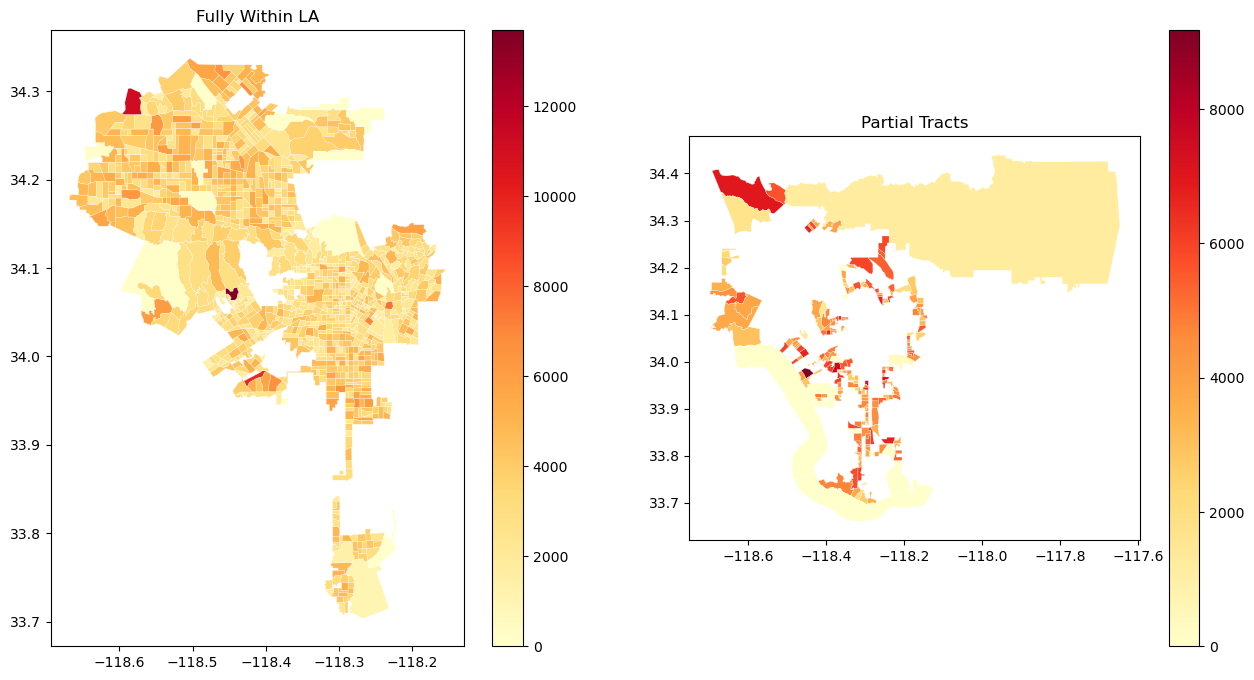

In [16]:
# Visually inspect where the population is spread in the Tracts
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Fully contained tracts
within.plot(
    column=pop_col,
    cmap="YlOrRd",
    legend=True,
    ax=axes[0],
    edgecolor="white",
    linewidth=0.2,
    missing_kwds={"color": "lightgray"}
)

axes[0].set_title("Fully Within LA")

# Partial tracts
partial.plot(
    column=pop_col,
    cmap="YlOrRd",
    legend=True,
    ax=axes[1],
    edgecolor="white",
    linewidth=0.2,
    missing_kwds={"color": "lightgray"}
)

axes[1].set_title("Partial Tracts")
plt.show()

Using tables and maps, we numerically and visually inspect how excluding the partial tracts might have an effect in terms of population we are missing in the analysis. However, we should also consider using `Median Household Income` since this socioeconomic factor will be used as part of our analysis; therefore, if there are tracts that don't have available income data, we should consider removing those first. In addition, we should also consider bringing in our main datasets - GTFS Schedule Data since if there are Tracts that don't have any bus/rail stops, this is also a factor to consider when excluding them from our analysis. 

### Using Median Household Income from ACS Estimates

In [17]:
income_col = "Median_Household_Income"

within_income = within[income_col]
partial_income = partial[income_col]

print("Fully within:")
print(within_income.describe())

print("\nPartial:")
print(partial_income.describe())

Fully within:
count      1080.000000
mean      87983.610185
std       41041.985523
min        5213.000000
25%       58691.000000
50%       79406.500000
75%      106449.750000
max      250001.000000
Name: Median_Household_Income, dtype: float64

Partial:
count       195.000000
mean     109749.364103
std       44826.731319
min       33134.000000
25%       76660.500000
50%       99806.000000
75%      132175.500000
max      250001.000000
Name: Median_Household_Income, dtype: float64


In [18]:
income_summary = pd.DataFrame({
    "Group": ["Fully Within", "Partial"],
    "Tract_Count": [len(within), len(partial)],
    "Valid_Tract_Count": [
        within[income_col].count(),
        partial[income_col].count()
    ],
    "Mean_Income": [
        within_income.mean(),
        partial_income.mean()
    ],
    "Median_Income": [
        within_income.median(),
        partial_income.median()
    ]
})

display(income_summary)

,Group,Tract_Count,Valid_Tract_Count,Mean_Income,Median_Income
0,Fully Within,1096,1080,87983.610185,79406.5
1,Partial,209,195,109749.364103,99806.0


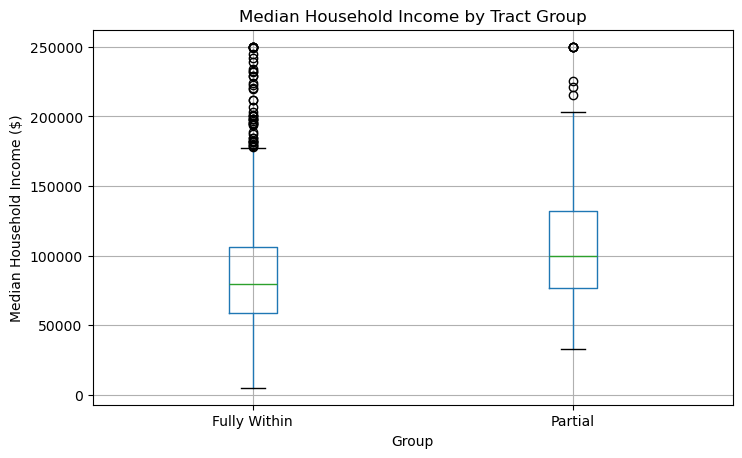

In [19]:
income_comparison = pd.DataFrame({
    "Income": pd.concat([
        within[income_col],
        partial[income_col]
    ]),
    "Group": (
        ["Fully Within"] * len(within)
        + ["Partial"] * len(partial)
    )
})

income_comparison.boxplot(
    column="Income",
    by="Group",
    figsize=(8, 5)
)

plt.title("Median Household Income by Tract Group")
plt.suptitle("")
plt.ylabel("Median Household Income ($)")
plt.show()

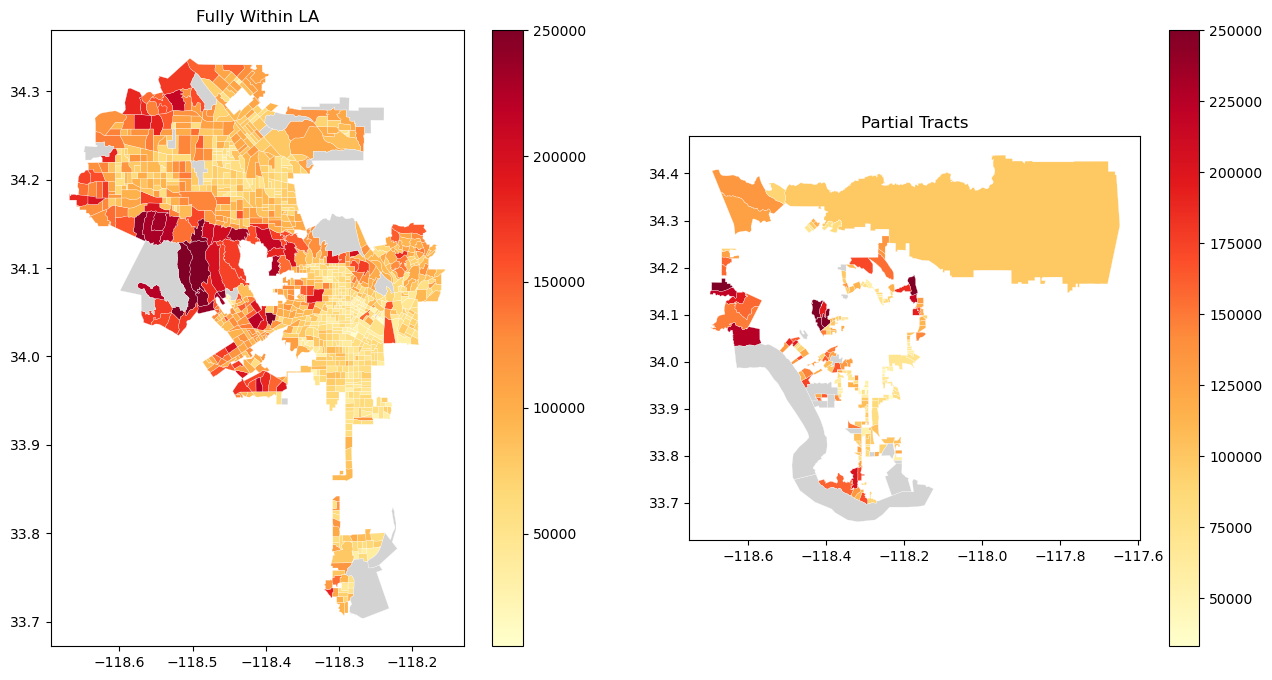

In [20]:
# Visually inspect how median income is spread in the Tracts
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Fully contained tracts
within.plot(
    column=income_col,
    cmap="YlOrRd",
    legend=True,
    ax=axes[0],
    edgecolor="white",
    linewidth=0.2,
    missing_kwds={"color": "lightgray"}
)

axes[0].set_title("Fully Within LA")

# Partial tracts
partial.plot(
    column=income_col,
    cmap="YlOrRd",
    legend=True,
    ax=axes[1],
    edgecolor="white",
    linewidth=0.2,
    missing_kwds={"color": "lightgray"}
)

axes[1].set_title("Partial Tracts")
plt.show()

### Using GTFS Schedule Data

In [21]:
stops = gpd.read_file("../data/all_stops_gdf_2026.csv")
stops

,field_1,stop_id,stop_name,stop_lat,stop_lon,mode,geometry
0,0,1,Paramount / Slauson,33.973248,-118.113113,bus,POINT (-118.113113 33.973248)
1,1,3,Jefferson / 10th,34.025471,-118.328402,bus,POINT (-118.328402 34.025471)
2,2,6,120th / Augustus F Hawkins,33.924696,-118.242222,bus,POINT (-118.242222 33.924696)
3,3,7,120th / Martin Luther King Hospital,33.924505,-118.240369,bus,POINT (-118.240369 33.924505)
4,4,12,15054 Sherman Way,34.201075,-118.461953,bus,POINT (-118.461953 34.201075)
...,...,...,...,...,...,...,...
12350,12350,81401S,Grand Ave Arts / Bunker Hill Station,34.05472448,-118.2515307,rail,POINT (-118.2515307 34.05472448)
12351,12351,81402,Historic Broadway Station,34.05215607,-118.2463211,rail,POINT (-118.2463211 34.05215607)
12352,12352,81402S,Historic Broadway Station,34.05215607,-118.2463211,rail,POINT (-118.2463211 34.05215607)
12353,12353,81403,Little Tokyo / Arts District Station,34.04884524,-118.2387567,rail,POINT (-118.2387567 34.04884524)


In [22]:
la_stops_gdf = stops_gdf[stops_gdf.within(city_bound)].copy()

NameError: name 'stops_gdf' is not defined

In [ ]:
# Spatial Join Bus/Rail Stops in LA City with Partial Census Tracts
partial_stop_join = gpd.sjoin(
    la_stops_gdf,
    partial[["GEOID", "geometry"]],
    how="inner",
    predicate="within"
)

In [ ]:
# Quick Summary
print("Stops by mode:")
print(partial_stop_join["mode"].value_counts())

print("\nUnique partial tracts with stops:")
print(partial_stop_join["GEOID"].nunique())

print("\nPartial tracts without stops:")
print(len(partial) - partial_stop_join["GEOID"].nunique())

In [ ]:
# Inspect the 11 tracts with stops
partial_with_stops = partial.merge(
    partial_stop_join[["GEOID"]].drop_duplicates(),
    on="GEOID",
    how="inner"
)

display(
    partial_with_stops[
        ["GEOID", pop_col, income_col]
    ]
)

In [ ]:
# Identify partial tracts without transit stops
partial_without_stops = partial.merge(
    partial_stop_join[["GEOID"]].drop_duplicates(),
    on="GEOID",
    how="left",
    indicator=True
)

partial_without_stops = partial_without_stops[
    partial_without_stops["_merge"] == "left_only"
].copy()

# Compare the two groups
comparison = pd.DataFrame({
    "Group": ["With Stops", "Without Stops"],
    "Tract_Count": [
        len(partial_with_stops),
        len(partial_without_stops)
    ],
    "Total_Population": [
        partial_with_stops[pop_col].sum(),
        partial_without_stops[pop_col].sum()
    ],
    "Median_Population": [
        partial_with_stops[pop_col].median(),
        partial_without_stops[pop_col].median()
    ],
    "Median_HH_Income": [
        partial_with_stops[income_col].median(),
        partial_without_stops[income_col].median()
    ]
})

display(comparison)